In [ ]:
#ANALISIS EXPLORATORIO DE LA DATA:
#1 Limpieza y resumen automático del dataset
#2 Detección de valores nulos y duplicados
#3 Distribuciones, boxplots y pairplots
#4 Correlaciones entre variables
#5 Interpretación automática de los primeros hallazgos

In [ ]:
!pip install ucimlrepo

In [ ]:
# PASO 1: Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from ucimlrepo import fetch_ucirepo
from sklearn.impute import SimpleImputer

In [ ]:
# Configuración visual
#ej. whitegrid agrega un fondo blanco con líneas de cuadrícula suaves. font_scale aumenta ligeramente el tamaño de las fuentes
sns.set(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.figsize"] = (8, 5)

In [ ]:
# PASO 2: Cargar dataset
# fetch dataset
autism_screening_adult = fetch_ucirepo(id=426)
df= autism_screening_adult.data.features.copy()
df['class'] = autism_screening_adult.data.targets['class']
#print(df)


In [ ]:
# Vista general
print("Dimensiones del dataset:", df.shape)
display(df['class'])


Dimensiones del dataset: (704, 21)


,class
0,NO
1,NO
2,YES
3,NO
4,NO
...,...
699,YES
700,NO
701,YES
702,NO


In [ ]:
# PASO 3: Información general
print("\n--- Información del dataset ---")
display(df.info())


--- Información del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 704 entries, 0 to 703
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   A1_Score         704 non-null    int64  
 1   A2_Score         704 non-null    int64  
 2   A3_Score         704 non-null    int64  
 3   A4_Score         704 non-null    int64  
 4   A5_Score         704 non-null    int64  
 5   A6_Score         704 non-null    int64  
 6   A7_Score         704 non-null    int64  
 7   A8_Score         704 non-null    int64  
 8   A9_Score         704 non-null    int64  
 9   A10_Score        704 non-null    int64  
 10  age              702 non-null    float64
 11  gender           704 non-null    object 
 12  ethnicity        609 non-null    object 
 13  jaundice         704 non-null    object 
 14  family_pdd       704 non-null    object 
 15  country_of_res   704 non-null    object 
 16  used_app_before  704 non-null

None

In [ ]:
print("\n--- Estadísticas descriptivas ---")
display(df.describe())


--- Estadísticas descriptivas ---


,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,result
count,704.000000,704.000000,704.000000,704.000000,704.000000,704.000000,704.000000,704.000000,704.000000,704.000000,702.000000,704.000000
mean,0.721591,0.453125,0.457386,0.495739,0.498580,0.284091,0.417614,0.649148,0.323864,0.573864,29.698006,4.875000
std,0.448535,0.498152,0.498535,0.500337,0.500353,0.451301,0.493516,0.477576,0.468281,0.494866,16.507465,2.501493
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,21.000000,3.000000
50%,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,27.000000,4.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,35.000000,7.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,383.000000,10.000000


In [ ]:
# PASO 4: Verificar valores nulos, duplicados y errores
print("\nValores nulos por columna:\n", df.isnull().sum())
print("\nDuplicados:\n", df.duplicated().sum())


Valores nulos por columna:
 A1_Score            0
A2_Score            0
A3_Score            0
A4_Score            0
A5_Score            0
A6_Score            0
A7_Score            0
A8_Score            0
A9_Score            0
A10_Score           0
age                 2
gender              0
ethnicity          95
jaundice            0
family_pdd          0
country_of_res      0
used_app_before     0
result              0
age_desc            0
relation           95
class               0
dtype: int64

Duplicados:
 5


In [ ]:
# PASO 4.5 Imputar clases

#verificación de valores extraños para edad
df.loc[(df['age'] < 0) | (df['age'] > 150), 'age'] = np.nan

#imputación de edad
imp_age = SimpleImputer(strategy="median")
df["age"] = imp_age.fit_transform(df[["age"]])[:, 0]

#imputación de etnia
imp_ethnicity = SimpleImputer(strategy="most_frequent")
df["ethnicity"] = imp_ethnicity.fit_transform(df[["ethnicity"]])[:, 0]

#imputación de relación
imp_relation = SimpleImputer(strategy="most_frequent")
df["relation"] = imp_relation.fit_transform(df[["relation"]])[:, 0]

In [ ]:
# PASO 4.6 comprobar imputacion
print("\nValores nulos por columna:\n", df.isnull().sum())
print("\nDuplicados:", df.duplicated().sum())


Valores nulos por columna:
 A1_Score           0
A2_Score           0
A3_Score           0
A4_Score           0
A5_Score           0
A6_Score           0
A7_Score           0
A8_Score           0
A9_Score           0
A10_Score          0
age                0
gender             0
ethnicity          0
jaundice           0
family_pdd         0
country_of_res     0
used_app_before    0
result             0
age_desc           0
relation           0
class              0
dtype: int64

Duplicados: 5


In [ ]:
#Paso 4.7 Eliminar los duplicados

# Eliminar los duplicados
df.drop_duplicates(inplace=True)

# Verificar el estado final de nulos y duplicados
print("Valores nulos por columna (después de limpieza):")
print(df.isnull().sum())
print("Duplicados después de la eliminación:", df.duplicated().sum())

Valores nulos por columna (después de limpieza):
A1_Score           0
A2_Score           0
A3_Score           0
A4_Score           0
A5_Score           0
A6_Score           0
A7_Score           0
A8_Score           0
A9_Score           0
A10_Score          0
age                0
gender             0
ethnicity          0
jaundice           0
family_pdd         0
country_of_res     0
used_app_before    0
result             0
age_desc           0
relation           0
class              0
dtype: int64
Duplicados después de la eliminación: 0


In [ ]:
# PASO 4.8: Información general
print("\n--- Información del dataset ---")
display(df.info())


--- Información del dataset ---
<class 'pandas.core.frame.DataFrame'>
Index: 699 entries, 0 to 703
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   A1_Score         699 non-null    int64  
 1   A2_Score         699 non-null    int64  
 2   A3_Score         699 non-null    int64  
 3   A4_Score         699 non-null    int64  
 4   A5_Score         699 non-null    int64  
 5   A6_Score         699 non-null    int64  
 6   A7_Score         699 non-null    int64  
 7   A8_Score         699 non-null    int64  
 8   A9_Score         699 non-null    int64  
 9   A10_Score        699 non-null    int64  
 10  age              699 non-null    float64
 11  gender           699 non-null    object 
 12  ethnicity        699 non-null    object 
 13  jaundice         699 non-null    object 
 14  family_pdd       699 non-null    object 
 15  country_of_res   699 non-null    object 
 16  used_app_before  699 non-null    o

None

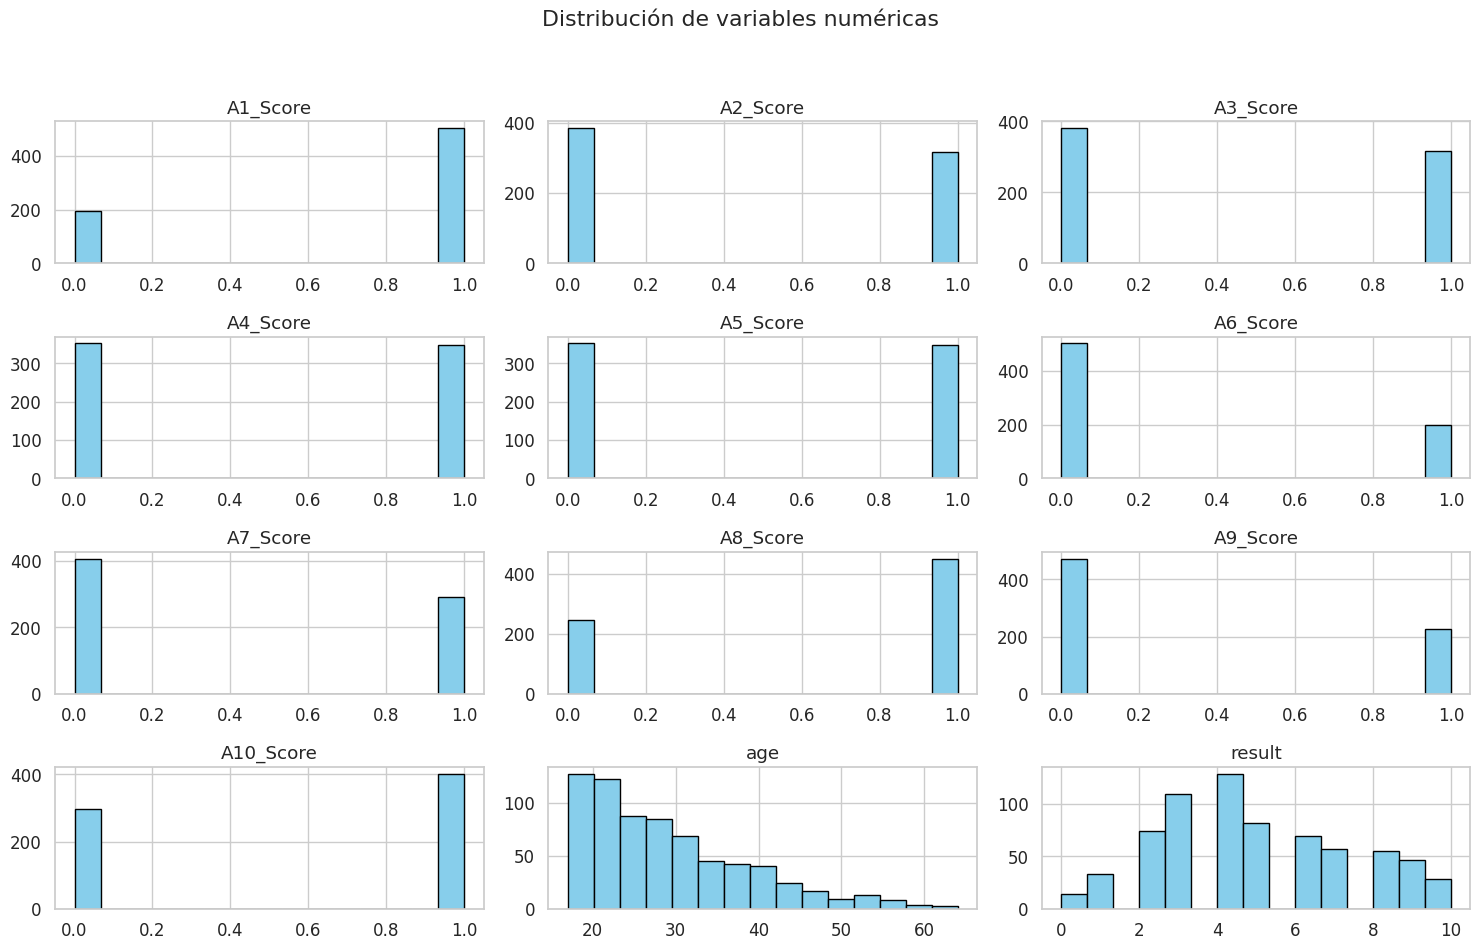

In [ ]:
# PASO 5: Distribución de variables numéricas
# Obtener las columnas numéricas del dataset actual
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

df[num_cols].hist(bins=15, figsize=(15, 10), color='skyblue', edgecolor='black')
plt.suptitle("Distribución de variables numéricas")
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajustar diseño para evitar superposición del título
plt.show()

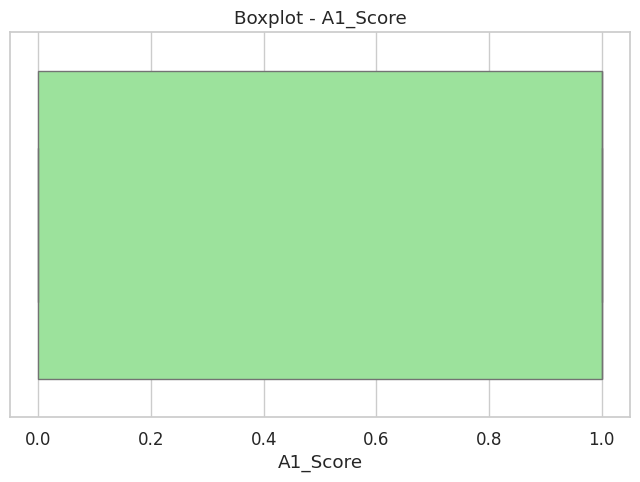

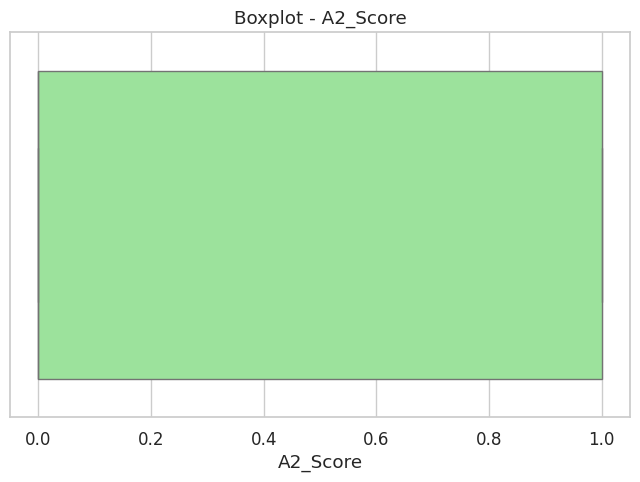

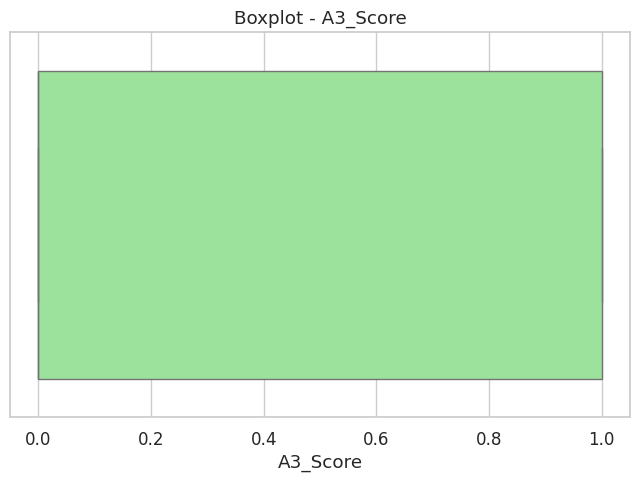

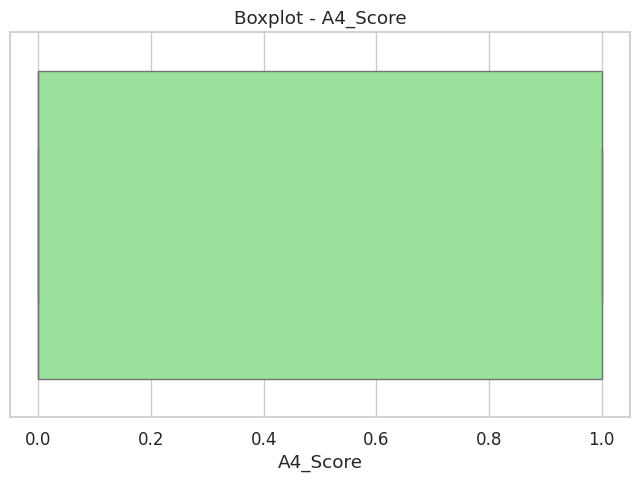

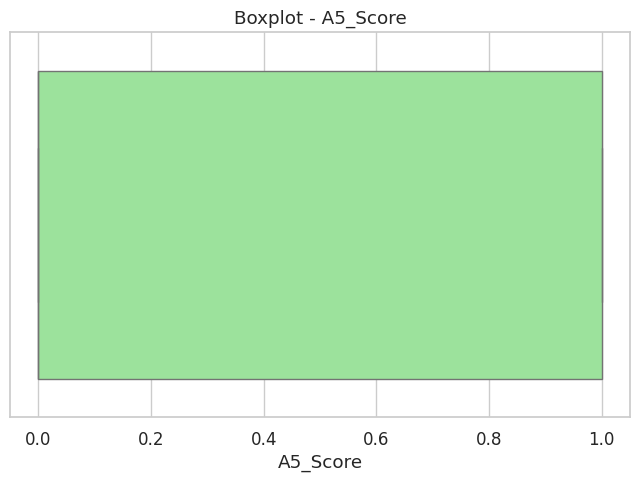

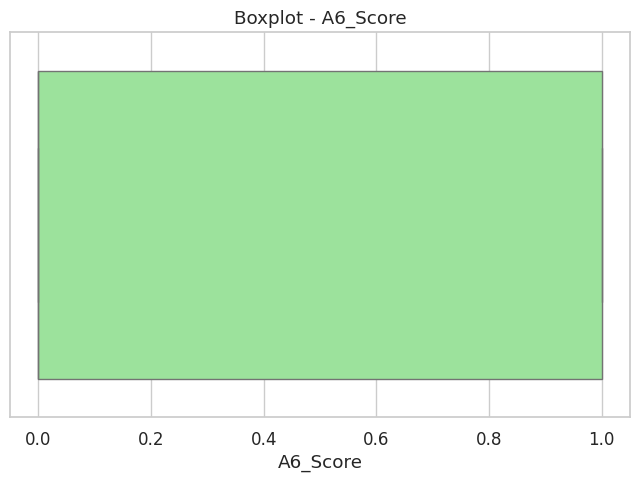

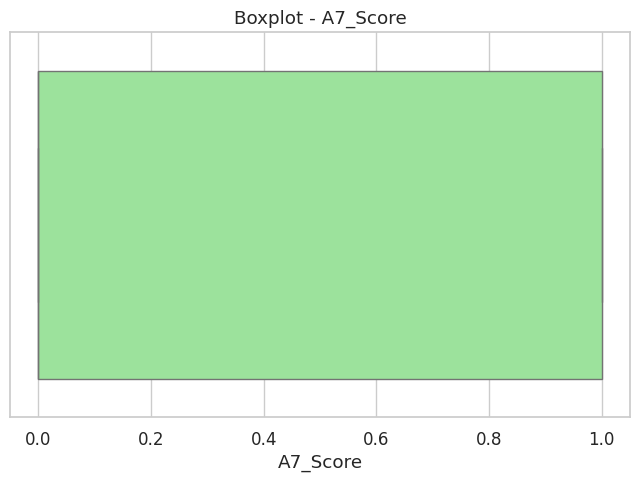

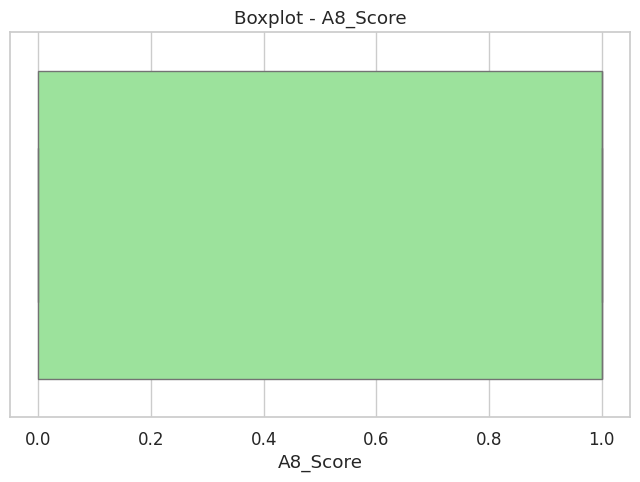

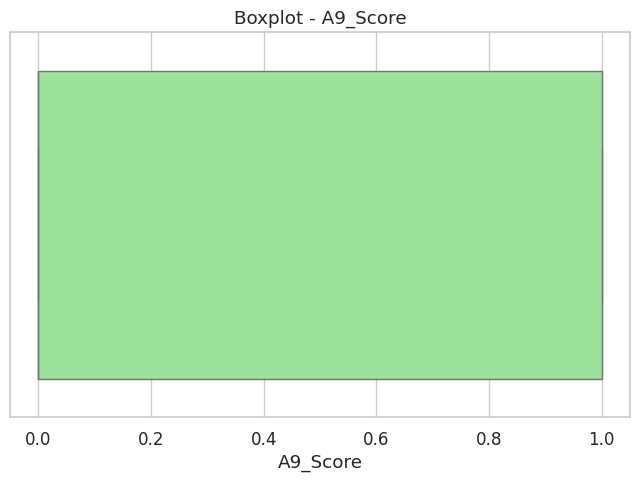

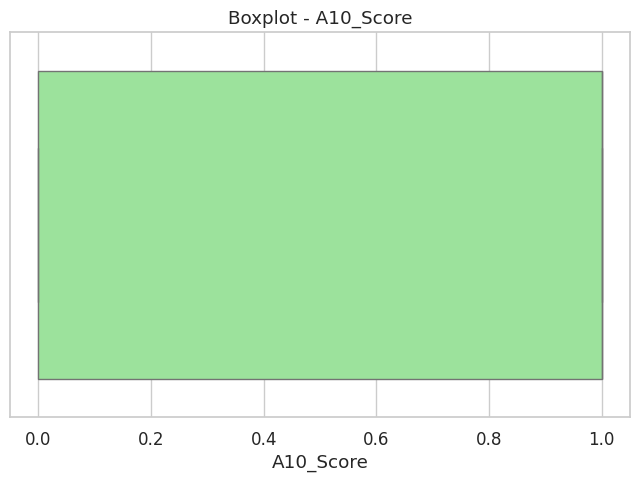

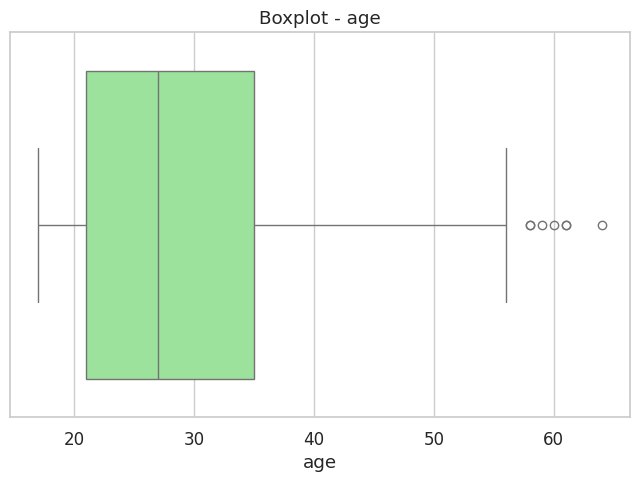

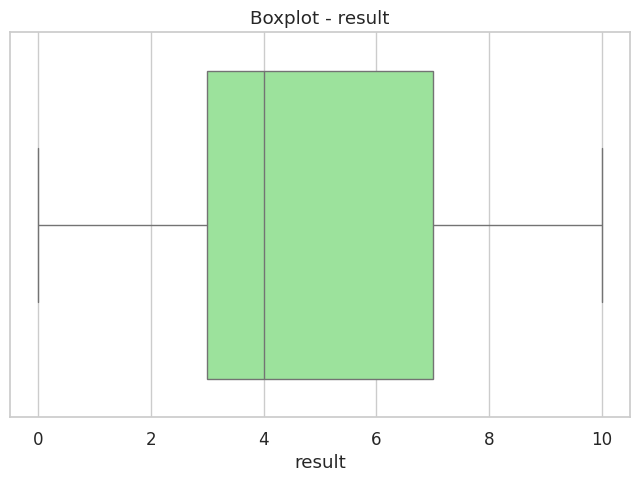

In [ ]:
# PASO 6: Boxplots para detectar outliers
for col in num_cols:
    sns.boxplot(x=df[col], color="lightgreen")
    plt.title(f"Boxplot - {col}")
    plt.show()

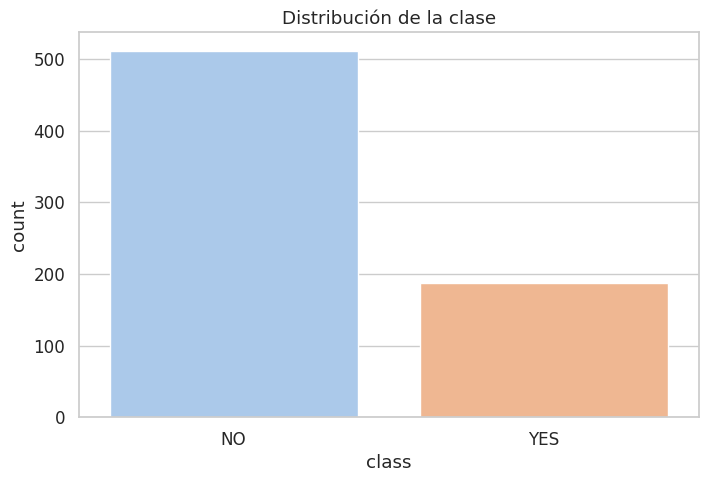

In [ ]:
# PASO 7: Análisis univariante de la variable categórica
sns.countplot(x="class", hue="class", data=df, palette="pastel", legend=False)
plt.title("Distribución de la clase")
plt.show()

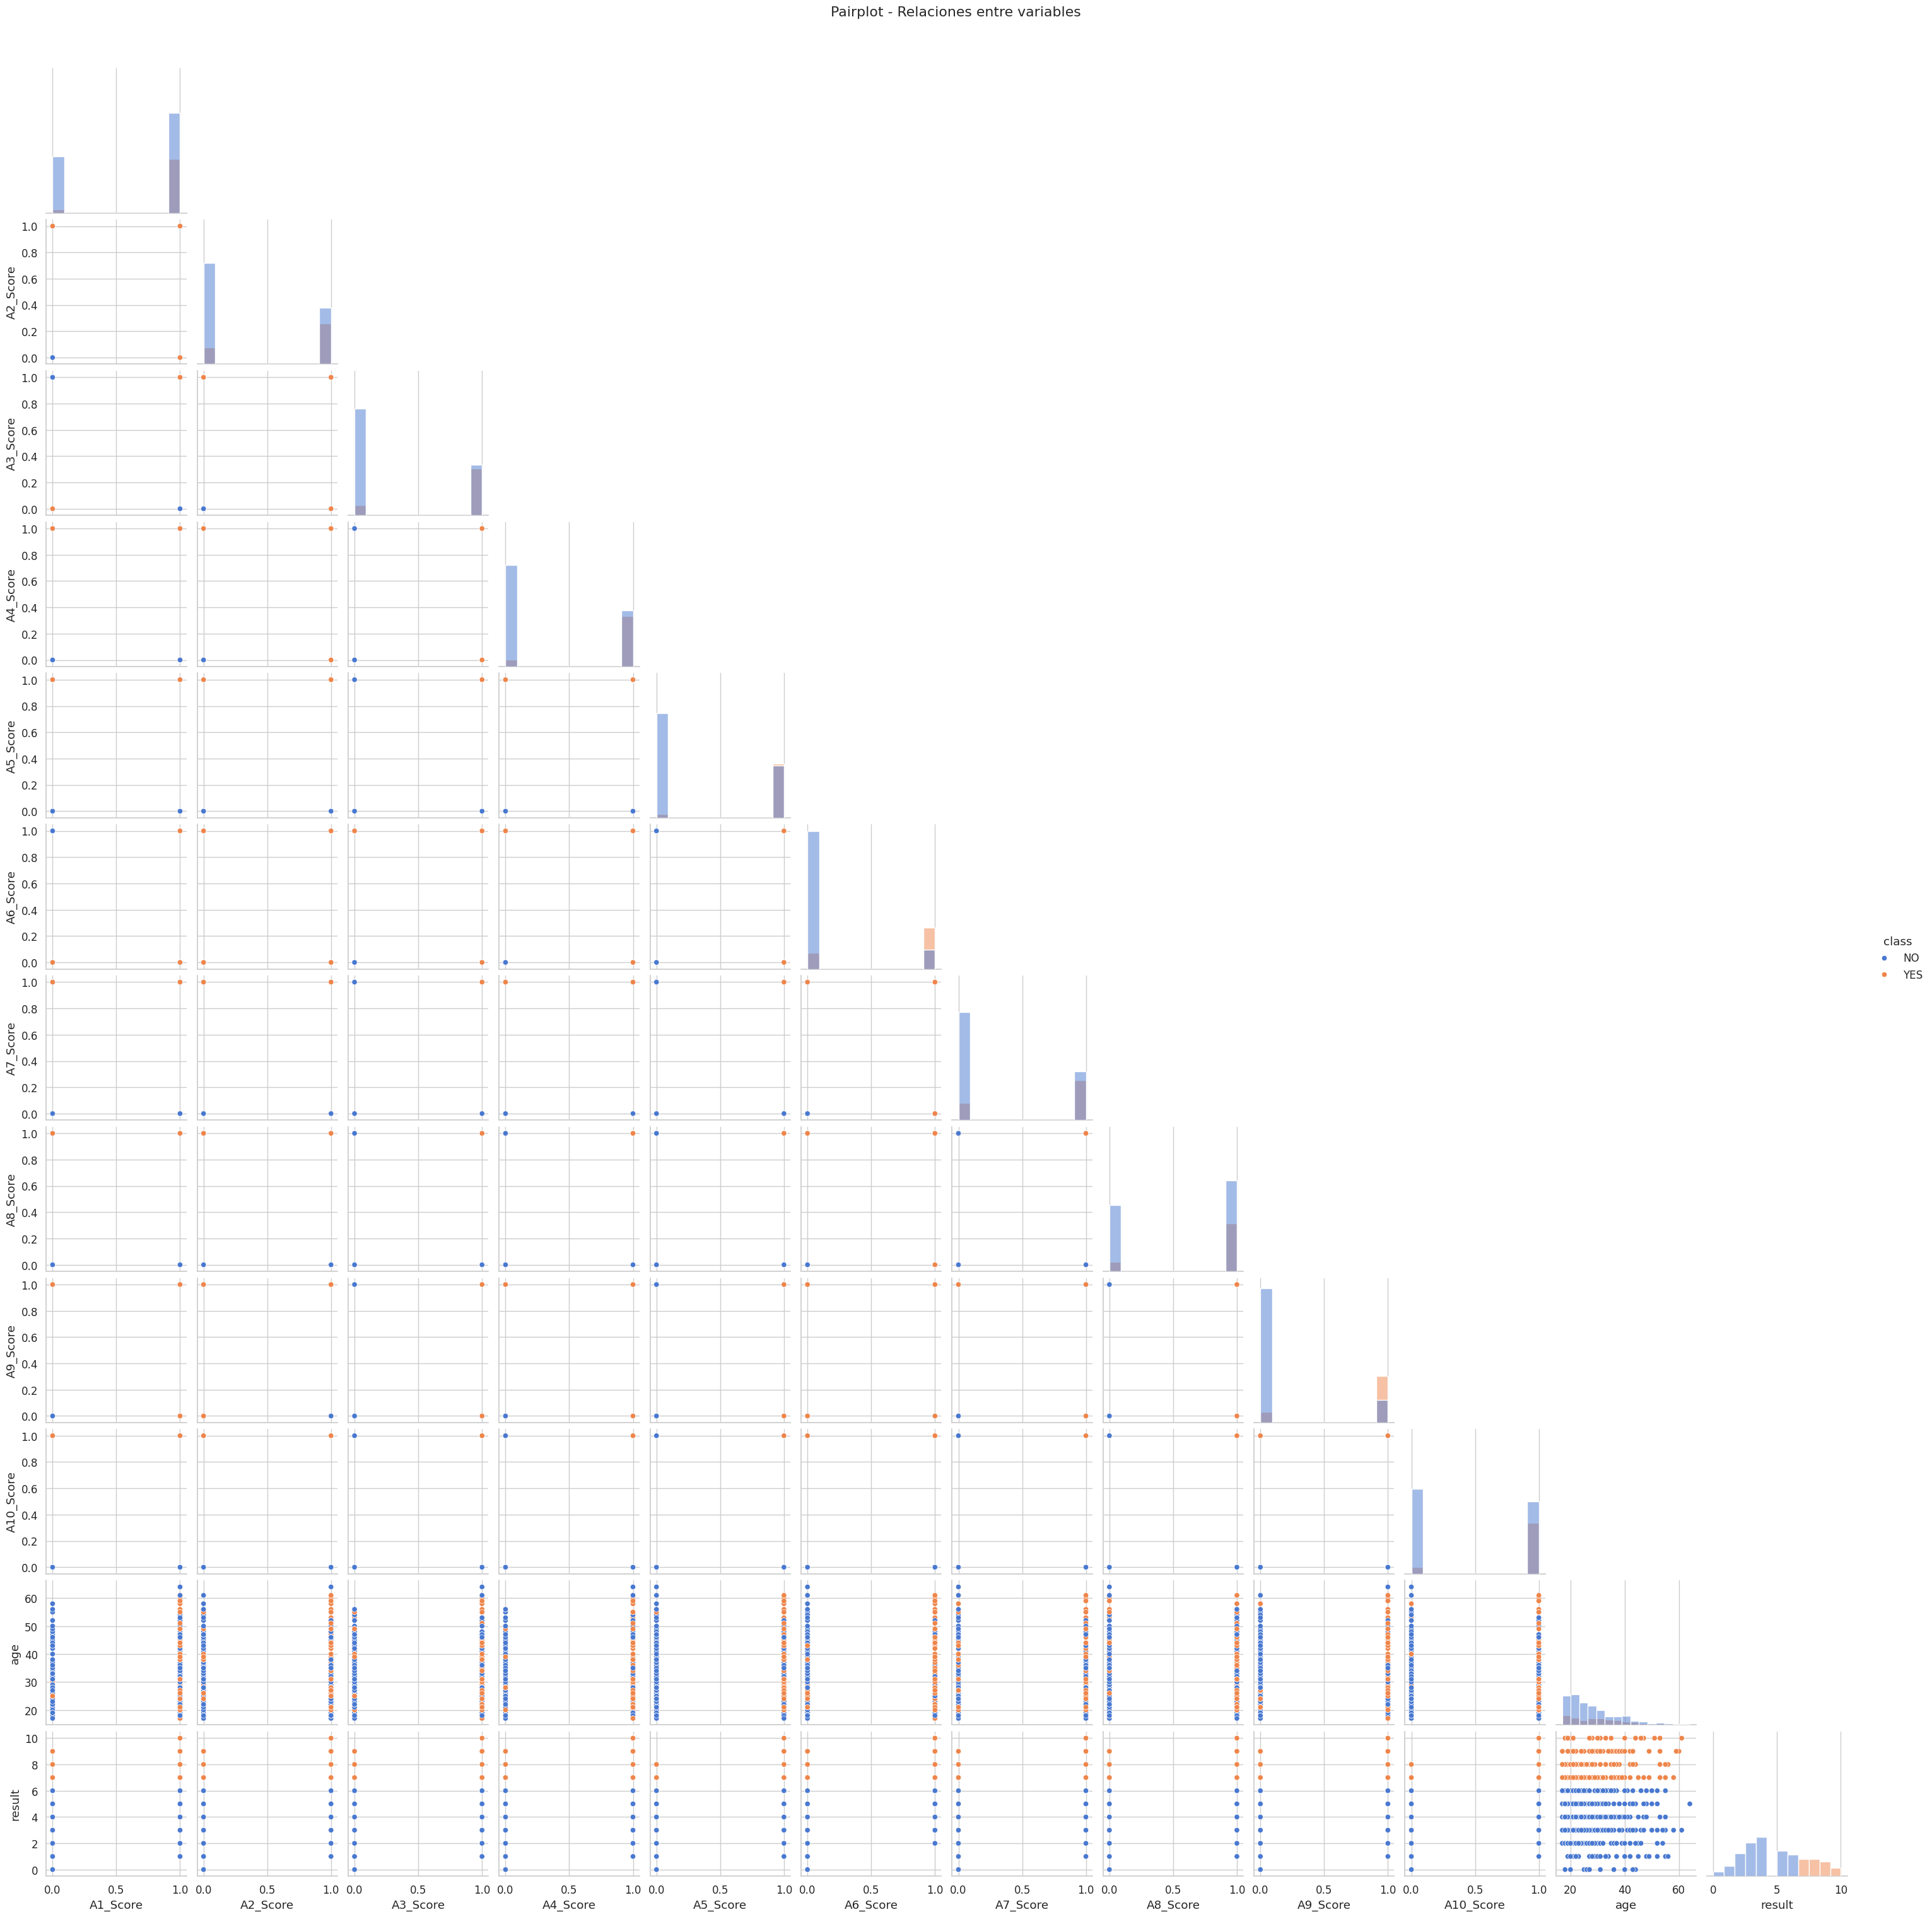

In [ ]:
# PASO 8: Análisis bivariante
sns.pairplot(df, hue="class", diag_kind="hist", corner=True)
plt.suptitle("Pairplot - Relaciones entre variables", y=1.02)
plt.show()

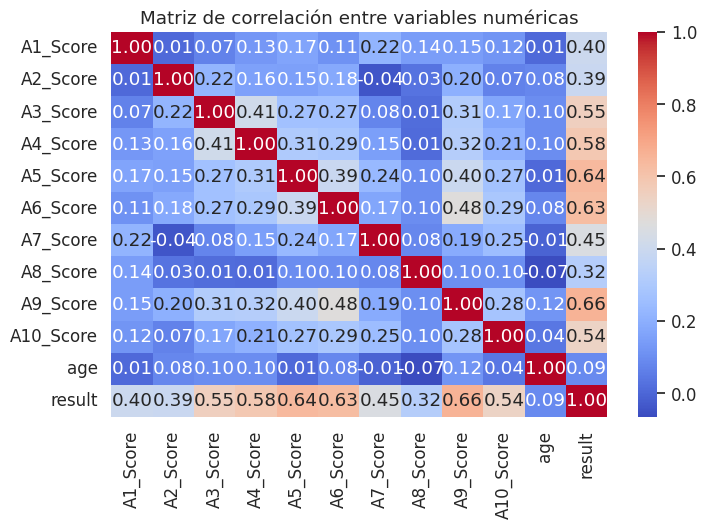

In [ ]:
# PASO 9: Matriz de correlación
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación entre variables numéricas")
plt.show()

In [ ]:
print("\n=========================== PASO 10 ===========================")
print(" Preparación de variables, preprocesamiento y modelo base\n")

# 1. Separar características (X) y objetivo (y)
X = df.drop(columns=['class', 'age_desc'])
y = df['class']

# 2. Codificar la clase
codificador_clase = LabelEncoder()
y = codificador_clase.fit_transform(y)

print("Clases codificadas:", list(codificador_clase.classes_))

# 3. Columnas numéricas y categóricas
columnas_numericas = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
columnas_categoricas = X.select_dtypes(include=['object']).columns.tolist()

print("\nColumnas numéricas:", columnas_numericas)
print("Columnas categóricas:", columnas_categoricas)

# 4. Preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), columnas_numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), columnas_categoricas)
    ]
)

# 5. División train/test
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("\nTamaño de entrenamiento:", X_entrenamiento.shape)
print("Tamaño de prueba:", X_prueba.shape)

# 6. Pipeline base | tipo de clasificador: Gaussiano (sin optimización)
modelo_nb_base = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('clasificador', GaussianNB())
])



=========================== PASO 10 ===========================
 Preparación de variables, preprocesamiento y modelo base

Clases codificadas: ['NO', 'YES']

Columnas numéricas: ['A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'result']
Columnas categóricas: ['gender', 'ethnicity', 'jaundice', 'family_pdd', 'country_of_res', 'used_app_before', 'relation']

Tamaño de entrenamiento: (489, 19)
Tamaño de prueba: (210, 19)


In [ ]:
# ================================================================
# PASO 11. FUNCIONES PARA CALCULAR Y MOSTRAR MÉTRICAS
# ================================================================

from sklearn.metrics import (
    accuracy_score, confusion_matrix, roc_curve, auc,
    classification_report
)
import matplotlib.pyplot as plt

def calcular_metricas(y_real, y_predicho):
    tn, fp, fn, tp = confusion_matrix(y_real, y_predicho).ravel()

    exactitud = (tp + tn) / (tp + tn + fp + fn)
    sensibilidad = tp / (tp + fn) if (tp + fn) != 0 else 0
    especificidad = tn / (tn + fp) if (tn + fp) != 0 else 0
    vpp = tp / (tp + fp) if (tp + fp) != 0 else 0
    vpn = tn / (tn + fn) if (tn + fn) != 0 else 0

    return exactitud, sensibilidad, especificidad, vpp, vpn, tn, fp, fn, tp

def reporte_completo(nombre, modelo, y_prueba, y_pred, y_pred_proba):
    print("\n============================================================")
    print(f" RESULTADOS DEL MODELO: {nombre}")
    print("============================================================")

    tn, fp, fn, tp = confusion_matrix(y_prueba, y_pred).ravel()
    print(" Matriz de Confusión:")
    print("------------------------------------------------------------")
    print(f"                Predicción")
    print(f"             Neg     |    Pos")
    print(f"Real Neg  |  {tn:4d}   |   {fp:4d}")
    print(f"Real Pos  |  {fn:4d}   |   {tp:4d}\n")
    print(f"VN: {tn:4d} | FP: {fp:4d}")
    print(f"FN: {fn:4d} | VP: {tp:4d}")
    print("------------------------------------------------------------")

    exactitud, sens, esp, vpp, vpn, _, _, _, _ = calcular_metricas(y_prueba, y_pred)

    print(" Métricas derivadas:")
    print("------------------------------------------------------------")
    print(f" Exactitud:                      {exactitud:.4f}")
    print(f" Sensibilidad (Recall +):        {sens:.4f}")
    print(f" Especificidad (Recall -):       {esp:.4f}")
    print(f" VPP (Precisión Positiva):       {vpp:.4f}")
    print(f" VPN (Precisión Negativa):       {vpn:.4f}\n")

    print("------------------------------------------------------------")
    print(" Reporte de Clasificación:")
    print("------------------------------------------------------------")
    print(classification_report(y_prueba, y_pred,
                               target_names=["NO Autismo", "SÍ Autismo"]))

    fpr, tpr, _ = roc_curve(y_prueba, y_pred_proba)
    valor_auc = auc(fpr, tpr)

    print(f" AUC ROC: {valor_auc:.4f}\n")

    plt.figure(figsize=(7,5))
    plt.plot(fpr, tpr, label=f"AUC = {valor_auc:.3f}")
    plt.plot([0,1], [0,1], 'k--')
    plt.title(f"Curva ROC - {nombre}")
    plt.xlabel("Falsos Positivos")
    plt.ylabel("Verdaderos Positivos")
    plt.legend()
    plt.grid(True)
    plt.show()


=========================== CASO 1 ===========================
 Modelo Naive Bayes SIN optimización de parámetros


 RESULTADOS DEL MODELO: Naive Bayes - Caso 1 (Sin optimización)
 Matriz de Confusión:
------------------------------------------------------------
                Predicción
             Neg     |    Pos
Real Neg  |    14   |    140
Real Pos  |     4   |     52

VN:   14 | FP:  140
FN:    4 | VP:   52
------------------------------------------------------------
 Métricas derivadas:
------------------------------------------------------------
 Exactitud:                      0.3143
 Sensibilidad (Recall +):        0.9286
 Especificidad (Recall -):       0.0909
 VPP (Precisión Positiva):       0.2708
 VPN (Precisión Negativa):       0.7778

------------------------------------------------------------
 Reporte de Clasificación:
------------------------------------------------------------
              precision    recall  f1-score   support

  NO Autismo       0.78      0.0

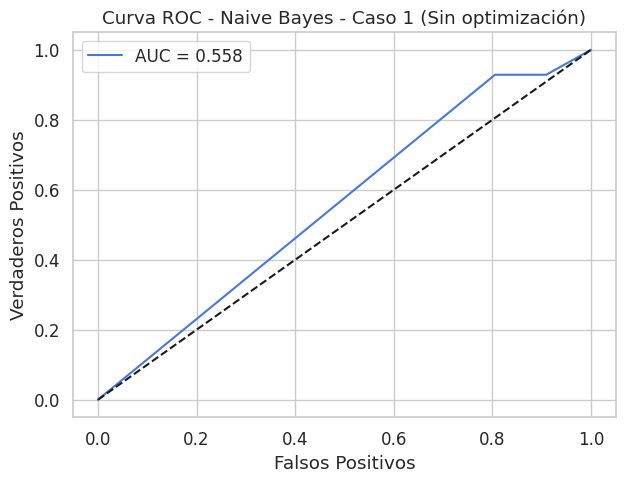

In [ ]:
print("\n=========================== CASO 1 ===========================")
print(" Modelo Naive Bayes SIN optimización de parámetros\n")

modelo_nb_base.fit(X_entrenamiento, y_entrenamiento)

y_pred_base = modelo_nb_base.predict(X_prueba)
y_proba_base = modelo_nb_base.predict_proba(X_prueba)[:, 1]

reporte_completo(
    "Naive Bayes - Caso 1 (Sin optimización)",
    modelo_nb_base,
    y_prueba,
    y_pred_base,
    y_proba_base
)


=========================== CASO 2 ===========================
Optimización de hiperparámetros

Mejor var_smoothing encontrado: 1.0
Exactitud obtenida en test: 0.9714

 RESULTADOS DEL MODELO: Naive Bayes - Caso 2 (Optimización hiperparametros)
 Matriz de Confusión:
------------------------------------------------------------
                Predicción
             Neg     |    Pos
Real Neg  |   150   |      4
Real Pos  |     2   |     54

VN:  150 | FP:    4
FN:    2 | VP:   54
------------------------------------------------------------
 Métricas derivadas:
------------------------------------------------------------
 Exactitud:                      0.9714
 Sensibilidad (Recall +):        0.9643
 Especificidad (Recall -):       0.9740
 VPP (Precisión Positiva):       0.9310
 VPN (Precisión Negativa):       0.9868

------------------------------------------------------------
 Reporte de Clasificación:
------------------------------------------------------------
              precision

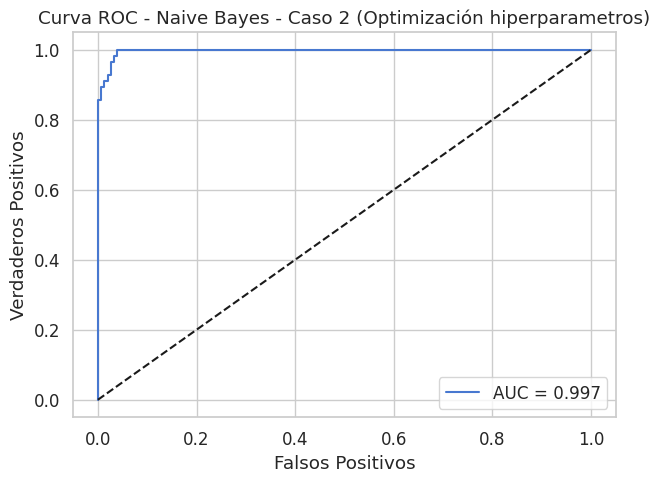

In [ ]:
print("\n=========================== CASO 2 ===========================")
print("Optimización de hiperparámetros\n")

valores_param = np.logspace(-10, 0, 40)

mejor_exactitud = -1
mejor_parametro = None
mejor_modelo_manual = None

for valor in valores_param:
    modelo_temp = Pipeline(steps=[
        ('preprocesador', preprocesador),
        ('clasificador', GaussianNB(var_smoothing=valor))
    ])

    modelo_temp.fit(X_entrenamiento, y_entrenamiento)

    y_pred_temp = modelo_temp.predict(X_prueba)
    acc_temp = accuracy_score(y_prueba, y_pred_temp)

    if acc_temp > mejor_exactitud:
        mejor_exactitud = acc_temp
        mejor_parametro = valor
        mejor_modelo_manual = modelo_temp

print(f"Mejor var_smoothing encontrado: {mejor_parametro}")
print(f"Exactitud obtenida en test: {mejor_exactitud:.4f}")

y_pred_mejor_manual = mejor_modelo_manual.predict(X_prueba)
y_proba_mejor_manual = mejor_modelo_manual.predict_proba(X_prueba)[:, 1]

reporte_completo(
    "Naive Bayes - Caso 2 (Optimización hiperparametros)",
    mejor_modelo_manual,
    y_prueba,
    y_pred_mejor_manual,
    y_proba_mejor_manual
)


=========================== CASO 3 ===========================
Optimización + Validación Cruzada (GridSearchCV)

Fitting 5 folds for each of 40 candidates, totalling 200 fits

 RESULTADOS DEL MODELO: Naive Bayes - Caso 3 (Optimizado + Validación cruzada)
 Matriz de Confusión:
------------------------------------------------------------
                Predicción
             Neg     |    Pos
Real Neg  |   148   |      6
Real Pos  |     1   |     55

VN:  148 | FP:    6
FN:    1 | VP:   55
------------------------------------------------------------
 Métricas derivadas:
------------------------------------------------------------
 Exactitud:                      0.9667
 Sensibilidad (Recall +):        0.9821
 Especificidad (Recall -):       0.9610
 VPP (Precisión Positiva):       0.9016
 VPN (Precisión Negativa):       0.9933

------------------------------------------------------------
 Reporte de Clasificación:
------------------------------------------------------------
            

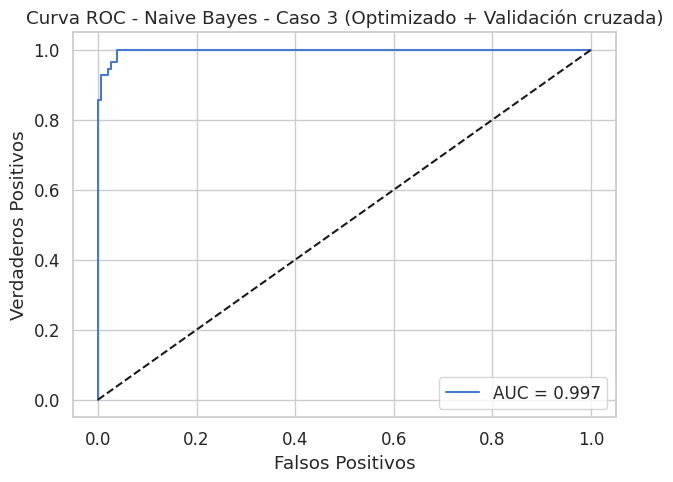

In [ ]:
print("\n=========================== CASO 3 ===========================")
print("Optimización + Validación Cruzada (GridSearchCV)\n")

parametros_grid = {
    'clasificador__var_smoothing': np.logspace(-9, 0, 40)
}

busqueda_grid = GridSearchCV(
    estimator=modelo_nb_base,
    param_grid=parametros_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

busqueda_grid.fit(X_entrenamiento, y_entrenamiento)

mejor_modelo_grid = busqueda_grid.best_estimator_

y_pred_grid = mejor_modelo_grid.predict(X_prueba)
y_proba_grid = mejor_modelo_grid.predict_proba(X_prueba)[:, 1]

reporte_completo(
    "Naive Bayes - Caso 3 (Optimizado + Validación cruzada)",
    mejor_modelo_grid,
    y_prueba,
    y_pred_grid,
    y_proba_grid
)

In [ ]:
# =============================
# COMPARACIÓN FINAL
# =============================

def metricas_completas(y_real, y_predicho):
    exactitud, sens, esp, vpp, vpn, tn, fp, fn, tp = calcular_metricas(y_real, y_predicho)
    return exactitud, sens, esp, vpp, vpn

# Obtener métricas de cada caso
acc1, sen1, esp1, vpp1, vpn1 = metricas_completas(y_prueba, y_pred_base)
acc2, sen2, esp2, vpp2, vpn2 = metricas_completas(y_prueba, y_pred_mejor_manual)
acc3, sen3, esp3, vpp3, vpn3 = metricas_completas(y_prueba, y_pred_grid)

# Imprimir tabla
print("\n=======================================================================")
print("                          COMPARACIÓN FINAL ")
print("=======================================================================")
print("Medidas                           Acc     Sen     Esp     VPP     VPN")
print("-----------------------------------------------------------------------")
print(f"Caso 1: NB sin optimizar          {acc1:.3f}   {sen1:.3f}   {esp1:.3f}   {vpp1:.3f}   {vpn1:.3f}")
print(f"Caso 2: Optimización simple       {acc2:.3f}   {sen2:.3f}   {esp2:.3f}   {vpp2:.3f}   {vpn2:.3f}")
print(f"Caso 3: Optimizacion + VC         {acc3:.3f}   {sen3:.3f}   {esp3:.3f}   {vpp3:.3f}   {vpn3:.3f}")
print("-----------------------------------------------------------------------\n")


                          COMPARACIÓN FINAL 
Medidas                           Acc     Sen     Esp     VPP     VPN
-----------------------------------------------------------------------
Caso 1: NB sin optimizar          0.314   0.929   0.091   0.271   0.778
Caso 2: Optimización simple       0.971   0.964   0.974   0.931   0.987
Caso 3: Optimizacion + VC         0.967   0.982   0.961   0.902   0.993
-----------------------------------------------------------------------

